# Qwen-27B Factor Path across Tokens and Components

The previous experiment found reliable, background-appropriate answer changes after decision-neutral weight and distance interventions, but neither the canonical L49 axis nor pilot-selected low-dimensional final-token subspaces mediated those effects.

[实验设置与运行说明](../../../docs/experiment_notes/09_appendix_factor_routes/f06079bad2d8d048.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 17 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 17 tracked cells.


## 1. Setup


In [2]:
%%cell_progress 1/17 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/17 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/17 Install and verify the multimodal environment
import importlib
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   6%|5         | 1/17 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/17 Verify GPU and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify GPU and Hugging Face access:  12%|#1        | 2/17 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/17 Lock the token-component path protocol
cell_stage('Freezing model, fresh support, pilot search, and confirmation gates')
import hashlib
import json
from datetime import datetime, timezone

MODEL_KEY = 'qwen27b'
MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_SLUG = 'Qwen__Qwen3.5-27B__373612cb'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
EXPECTED_LAYER_COUNT = 64
UPSTREAM_LAYER = 48
CANDIDATE_LAYERS = (49, 53, 57, 61)
CANDIDATE_COMPONENTS = ('attention', 'mlp', 'decoder')
CANDIDATE_SCOPES = (
    'question_tokens', 'options_tokens',
    'answer_instruction_tokens', 'final_prompt_token',
)
NEGATIVE_CONTROL_SCOPES = ('question_tokens',)
CAPTURE_LAYERS = (UPSTREAM_LAYER,) + CANDIDATE_LAYERS
UPSTREAM_SCOPE = 'options_tokens'
SEMANTIC_SCOPE = 'final_prompt_token'

SEED = 20261007
FACTORS = ('weight', 'distance')
FAMILIES_PER_FACTOR = 16
PILOT_PER_FACTOR = 4
CONFIRMATION_PER_FACTOR = FAMILIES_PER_FACTOR - PILOT_PER_FACTOR
EXPECTED_FAMILIES = len(FACTORS) * FAMILIES_PER_FACTOR
BACKGROUNDS = ('b1', 'b2')
MAPPING_VARIANTS = ('forward', 'reverse')
SITES_PER_FACTOR = 2
SITE_BATCH_SIZE = 4
CONFIRMATION_CONDITIONS = (
    'additive_total', 'primary_restore', 'secondary_restore',
    'joint_restore', 'joint_random', 'whole_donor',
    'natural_hybrid', 'self_replay',
)
BOOTSTRAP_REPLICATES = 10000
ALPHA = 0.05
ANSWER_SESOI_LOGODDS = 0.05
MEDIATION_SESOI_LOGODDS = 0.05
SMOKE_CENTERED_LOGPROB_TOLERANCE = 0.15
NORM_RELATIVE_TOLERANCE = 1e-3
IMAGE_TOKEN_ID_OVERRIDE = None

PRIOR_RECOMBINATION_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_decision_neutral_factor_semantic_mediation_v1'
)
PRIOR_MANIFEST_PATH = (
    PRIOR_RECOMBINATION_ROOT / 'decision_neutral_manifest.jsonl'
)
PRIOR_DISTRIBUTED_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_distributed_factor_mediator_subspace_v1'
)
PRIOR_DISTRIBUTED_DECISION_PATH = (
    PRIOR_DISTRIBUTED_ROOT / 'analysis'
    / 'distributed_mediator_decision.json'
)
PRIOR_DISTRIBUTED_RUN_PATH = PRIOR_DISTRIBUTED_ROOT / 'RUN_COMPLETE.json'

SHARED_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_factor_path_token_component_v2'
)
MANIFEST_PATH = SHARED_ROOT / 'fresh_decision_neutral_manifest.jsonl'
MANIFEST_LOCK_PATH = SHARED_ROOT / 'manifest_lock.json'
PROTOCOL_LOCK_PATH = SHARED_ROOT / 'frozen_protocol.json'
PILOT_DIR = SHARED_ROOT / 'pilot_family_shards'
CONFIRMATION_DIR = SHARED_ROOT / 'confirmation_family_shards'
ANALYSIS_DIR = SHARED_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
SELECTION_PATH = ANALYSIS_DIR / 'frozen_sites.json'
for path in (
    SHARED_ROOT, PILOT_DIR, CONFIRMATION_DIR, ANALYSIS_DIR, FIGURE_DIR,
):
    path.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value!r}'.encode('utf-8')).hexdigest()

for required in (
    PRIOR_MANIFEST_PATH, PRIOR_DISTRIBUTED_DECISION_PATH,
    PRIOR_DISTRIBUTED_RUN_PATH,
):
    assert required.is_file(), f'Missing prerequisite: {required}'
prior_distributed_decision = json.loads(
    PRIOR_DISTRIBUTED_DECISION_PATH.read_text(encoding='utf-8')
)
assert prior_distributed_decision['primary_decision'] == (
    'factor_effect_without_confirmed_distributed_mediator'
)

protocol_identity = {
    'schema_version': 'qwen27b-factor-path-token-component-1.1',
    'analysis_status': 'pilot-selected, fresh-support confirmation',
    'model_id': MODEL_ID,
    'revision': MODEL_REVISION,
    'upstream_site': [UPSTREAM_LAYER, UPSTREAM_SCOPE],
    'candidate_layers': list(CANDIDATE_LAYERS),
    'candidate_components': list(CANDIDATE_COMPONENTS),
    'candidate_scopes': list(CANDIDATE_SCOPES),
    'selection_excludes_scopes': list(NEGATIVE_CONTROL_SCOPES),
    'families_per_factor': FAMILIES_PER_FACTOR,
    'pilot_per_factor': PILOT_PER_FACTOR,
    'sites_per_factor': SITES_PER_FACTOR,
    'site_distinctness': 'selected sites must occupy distinct layers',
    'manifest_selection_policy': (
        'deterministic multi-start global scene-disjoint search; if no '
        'complete support is found, deterministic within-factor '
        'scene-disjoint supports with recorded cross-factor overlap'
    ),
    'immediate_prior_overlap_allowed': False,
    'confirmation_conditions': list(CONFIRMATION_CONDITIONS),
    'primary_unit': 'family average over two backgrounds',
    'answer_sesoi_logodds': ANSWER_SESOI_LOGODDS,
    'mediation_sesoi_logodds': MEDIATION_SESOI_LOGODDS,
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'excluded_manifest_sha256': sha256_file(PRIOR_MANIFEST_PATH),
    'prior_decision_sha256': sha256_file(PRIOR_DISTRIBUTED_DECISION_PATH),
    'seed': SEED,
}
if PROTOCOL_LOCK_PATH.is_file():
    previous_lock = json.loads(
        PROTOCOL_LOCK_PATH.read_text(encoding='utf-8')
    )
    assert previous_lock.get('identity') == protocol_identity, (
        'Existing protocol differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Model:', MODEL_ID, '@', MODEL_REVISION)
print('Candidate route sites:',
      len(CANDIDATE_LAYERS) * len(CANDIDATE_COMPONENTS)
      * len(CANDIDATE_SCOPES))
print('Pilot / confirmation per factor:',
      PILOT_PER_FACTOR, CONFIRMATION_PER_FACTOR)
print('Output:', SHARED_ROOT)


Lock the token-component path protocol:  18%|#7        | 3/17 [00:00<?, ?cell/s]

Model: Qwen/Qwen3.5-27B @ 373612cb4f9288fcf550b526d86d85febedd9801
Candidate route sites: 48
Pilot / confirmation per factor: 4 12
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_factor_path_token_component_v2


In [6]:
%%cell_progress 5/17 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  24%|##3       | 4/17 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


In [7]:
%%cell_progress 6/17 Build a fresh decision-neutral path manifest
cell_stage('Enumerating families disjoint from the previous recombination support')
import itertools
from collections import Counter, defaultdict

from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def write_jsonl_atomic(path, rows):
    temporary = Path(path).with_suffix(Path(path).suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(row, sort_keys=True) + '\n')
    temporary.replace(path)

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value!r}'.encode('utf-8')).hexdigest()

scene_records = read_jsonl(DATASET_DIR / 'scenes.jsonl')
scene_by_id = {str(row['scene_id']): row for row in scene_records}

def single_shape(scene):
    if len(scene['stacks']) != 2:
        return None
    left = [stack for stack in scene['stacks'] if stack['side'] == 'left']
    right = [stack for stack in scene['stacks'] if stack['side'] == 'right']
    if len(left) != 1 or len(right) != 1:
        return None
    return (
        int(left[0]['units']), int(left[0]['distance']),
        int(right[0]['units']), int(right[0]['distance']),
    )

scene_by_shape = {}
for scene in scene_records:
    shape = single_shape(scene)
    if shape is not None:
        assert shape not in scene_by_shape
        scene_by_shape[shape] = str(scene['scene_id'])
assert len(scene_by_shape) == 900, len(scene_by_shape)

excluded_rows = read_jsonl(PRIOR_MANIFEST_PATH)
excluded_scene_ids = {
    str(role['scene_id'])
    for row in excluded_rows for role in row['roles'].values()
}
assert len(excluded_scene_ids) == 288
prior_scene_ids = set(excluded_scene_ids)
results_root = PROJECT_ROOT / 'results'
if results_root.is_dir():
    prior_paths = sorted(
        path for path in results_root.rglob('*manifest*.jsonl')
        if SHARED_ROOT not in path.parents
    )
    for path in tqdm(prior_paths, desc='Auditing prior scene support', unit='file'):
        try:
            rows = read_jsonl(path)
        except Exception:
            continue
        for row in rows:
            for key, value in row.items():
                if key.endswith('_scene_id') and isinstance(value, (str, int)):
                    prior_scene_ids.add(str(value))
                elif key.endswith('_scene_ids') and isinstance(value, (list, tuple)):
                    prior_scene_ids.update(str(item) for item in value)
            if isinstance(row.get('roles'), dict):
                for role in row['roles'].values():
                    if isinstance(role, dict) and 'scene_id' in role:
                        prior_scene_ids.add(str(role['scene_id']))

def shape_for(side, units, distance, fixed_units, fixed_distance):
    if side == 'left':
        return (units, distance, fixed_units, fixed_distance)
    return (fixed_units, fixed_distance, units, distance)

def role_record(side, units, distance, fixed_units, fixed_distance):
    shape = shape_for(side, units, distance, fixed_units, fixed_distance)
    scene_id = scene_by_shape.get(shape)
    if scene_id is None:
        return None
    scene = scene_by_id[scene_id]
    return {
        'scene_id': scene_id,
        'units': int(units),
        'distance': int(distance),
        'side_torque': int(scene['derived'][f'{side}_torque']),
        'net_torque': int(scene['derived']['net_torque']),
        'outcome': str(scene['derived']['outcome']),
    }

def decision_neutral(roles):
    base = roles['anchor']['outcome']
    hybrid = roles['hybrid_b1']['outcome']
    return (
        base in ('left', 'right')
        and hybrid in ('left', 'right')
        and base != hybrid
        and all(
            roles[name]['outcome'] == base
            for name in ('source', 'target_b1', 'target_b2')
        )
        and roles['hybrid_b2']['outcome'] == hybrid
    )

if MANIFEST_PATH.is_file() and MANIFEST_LOCK_PATH.is_file():
    factor_manifest = read_jsonl(MANIFEST_PATH)
    lock = json.loads(MANIFEST_LOCK_PATH.read_text(encoding='utf-8'))
    assert lock['identity']['selected_count'] == len(factor_manifest)
    candidates = None
    cell_stage('Using the existing locked manifest')
else:
    candidates = []
    for side in ('left', 'right'):
        for fixed_units in range(1, 6):
            for fixed_distance in range(1, 7):
                for w0, w1 in itertools.permutations(range(1, 6), 2):
                    for d0 in range(1, 7):
                        for d1, d2 in itertools.combinations(
                            [value for value in range(1, 7) if value != d0], 2
                        ):
                            values = {
                                'anchor': (w0, d0), 'source': (w1, d0),
                                'target_b1': (w0, d1), 'hybrid_b1': (w1, d1),
                                'target_b2': (w0, d2), 'hybrid_b2': (w1, d2),
                            }
                            roles = {
                                name: role_record(
                                    side, units, distance,
                                    fixed_units, fixed_distance,
                                )
                                for name, (units, distance) in values.items()
                            }
                            if None in roles.values() or not decision_neutral(roles):
                                continue
                            family_id = 'neutral_weight_' + stable_key((
                                side, fixed_units, fixed_distance,
                                w0, w1, d0, d1, d2,
                            ))[:18]
                            candidates.append({
                                'family_id': family_id,
                                'factor': 'weight',
                                'changed_side': side,
                                'fixed_opposite_units': fixed_units,
                                'fixed_opposite_distance': fixed_distance,
                                'factor_sign': int(w1 > w0) - int(w1 < w0),
                                'roles': roles,
                            })

                for d0, d1 in itertools.permutations(range(1, 7), 2):
                    for w0 in range(1, 6):
                        for w1, w2 in itertools.combinations(
                            [value for value in range(1, 6) if value != w0], 2
                        ):
                            values = {
                                'anchor': (w0, d0), 'source': (w0, d1),
                                'target_b1': (w1, d0), 'hybrid_b1': (w1, d1),
                                'target_b2': (w2, d0), 'hybrid_b2': (w2, d1),
                            }
                            roles = {
                                name: role_record(
                                    side, units, distance,
                                    fixed_units, fixed_distance,
                                )
                                for name, (units, distance) in values.items()
                            }
                            if None in roles.values() or not decision_neutral(roles):
                                continue
                            family_id = 'neutral_distance_' + stable_key((
                                side, fixed_units, fixed_distance,
                                d0, d1, w0, w1, w2,
                            ))[:18]
                            candidates.append({
                                'family_id': family_id,
                                'factor': 'distance',
                                'changed_side': side,
                                'fixed_opposite_units': fixed_units,
                                'fixed_opposite_distance': fixed_distance,
                                'factor_sign': int(d1 > d0) - int(d1 < d0),
                                'roles': roles,
                            })

    assert all(decision_neutral(row['roles']) for row in candidates)
    for row in candidates:
        row['prior_overlap_count'] = sum(
            role['scene_id'] in prior_scene_ids
            for role in row['roles'].values()
        )
        row['transition'] = (
            row['roles']['anchor']['outcome'] + '->'
            + row['roles']['hybrid_b1']['outcome']
        )

    eligible_counts = {
        factor: sum(
            row['factor'] == factor
            and not ({
                role['scene_id'] for role in row['roles'].values()
            } & excluded_scene_ids)
            for row in candidates
        )
        for factor in FACTORS
    }

    def select_factor_support(factor, forbidden_scenes, attempt):
        groups = defaultdict(list)
        for row in candidates:
            if row['factor'] != factor:
                continue
            scene_ids = {
                role['scene_id'] for role in row['roles'].values()
            }
            if scene_ids & excluded_scene_ids:
                continue
            groups[(
                row['changed_side'], row['factor_sign'], row['transition']
            )].append(row)
        for key, rows in groups.items():
            rows.sort(key=lambda row: (
                row['prior_overlap_count'],
                stable_key((attempt, key, row['family_id'])),
            ))
        group_keys = sorted(
            groups,
            key=lambda key: stable_key((attempt, 'group', key)),
        )
        cursors = {key: 0 for key in group_keys}
        chosen = []
        used = set(forbidden_scenes)
        while len(chosen) < FAMILIES_PER_FACTOR:
            changed = False
            for key in group_keys:
                rows = groups[key]
                while cursors[key] < len(rows):
                    row = rows[cursors[key]]
                    cursors[key] += 1
                    scene_ids = {
                        role['scene_id'] for role in row['roles'].values()
                    }
                    if scene_ids & used:
                        continue
                    chosen.append(row)
                    used.update(scene_ids)
                    changed = True
                    break
                if len(chosen) == FAMILIES_PER_FACTOR:
                    break
            if not changed:
                break
        return chosen

    # The old one-pass weight-first selection could occupy nearly every
    # scene needed by distance families. Search both orders with deterministic
    # tie-breakings before allowing overlap between the two factor supports.
    selected_by_factor = None
    selected_attempt = None
    selection_policy = None
    scarcity_order = tuple(sorted(
        FACTORS, key=lambda value: eligible_counts[value]
    ))
    factor_orders = (scarcity_order, tuple(reversed(scarcity_order)))
    for attempt in range(512):
        order = factor_orders[attempt % len(factor_orders)]
        current = {}
        globally_used = set()
        for factor in order:
            chosen = select_factor_support(
                factor, globally_used,
                1000 * attempt + FACTORS.index(factor),
            )
            if len(chosen) != FAMILIES_PER_FACTOR:
                break
            current[factor] = chosen
            globally_used.update(
                role['scene_id']
                for row in chosen for role in row['roles'].values()
            )
        if set(current) == set(FACTORS):
            selected_by_factor = current
            selected_attempt = attempt
            selection_policy = 'global_scene_disjoint_multistart'
            break

    if selected_by_factor is None:
        selected_by_factor = {}
        for factor in FACTORS:
            best = []
            for attempt in range(512):
                chosen = select_factor_support(
                    factor, set(),
                    100000 + 1000 * attempt + FACTORS.index(factor),
                )
                if len(chosen) > len(best):
                    best = chosen
                if len(chosen) == FAMILIES_PER_FACTOR:
                    break
            assert len(best) == FAMILIES_PER_FACTOR, (
                factor, len(best), eligible_counts[factor]
            )
            selected_by_factor[factor] = best
        selected_attempt = None
        selection_policy = 'within_factor_scene_disjoint_fallback'

    selected = []
    for factor in FACTORS:
        for index, original in enumerate(selected_by_factor[factor]):
            row = dict(original)
            row['split'] = (
                'pilot' if index < PILOT_PER_FACTOR else 'confirmation'
            )
            row['counterbalance_phase'] = (
                int(stable_key(f"mapping:{row['family_id']}")[:8], 16) % 2
            )
            selected.append(row)

    factor_manifest = sorted(selected, key=lambda row: row['family_id'])
    factor_scene_sets = {
        factor: {
            role['scene_id']
            for row in factor_manifest if row['factor'] == factor
            for role in row['roles'].values()
        }
        for factor in FACTORS
    }
    cross_factor_scene_ids = set.intersection(*factor_scene_sets.values())
    global_scene_disjoint = not cross_factor_scene_ids
    write_jsonl_atomic(MANIFEST_PATH, factor_manifest)
    manifest_identity = {
        'schema_version': 'fresh-factor-path-manifest-1.1',
        'selected_count': len(factor_manifest),
        'counts_by_factor': dict(Counter(
            row['factor'] for row in factor_manifest
        )),
        'counts_by_split': dict(Counter(
            row['split'] for row in factor_manifest
        )),
        'scene_disjoint': bool(global_scene_disjoint),
        'within_factor_scene_disjoint': True,
        'cross_factor_scene_overlap_count': len(cross_factor_scene_ids),
        'selection_policy': selection_policy,
        'selection_attempt': selected_attempt,
        'selection_uses_model_outputs': False,
        'decision_neutral_donor': True,
        'two_background_fanout': True,
        'family_ids': [row['family_id'] for row in factor_manifest],
        'seed': SEED,
    }
    write_json_atomic(MANIFEST_LOCK_PATH, {
        'identity': manifest_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

assert len(factor_manifest) == EXPECTED_FAMILIES
assert Counter(row['factor'] for row in factor_manifest) == {
    factor: FAMILIES_PER_FACTOR for factor in FACTORS
}
all_selected_scenes = [
    role['scene_id']
    for row in factor_manifest for role in row['roles'].values()
]
factor_scene_lists = {
    factor: [
        role['scene_id']
        for row in factor_manifest if row['factor'] == factor
        for role in row['roles'].values()
    ]
    for factor in FACTORS
}
assert all(
    len(values) == len(set(values))
    for values in factor_scene_lists.values()
)
factor_scene_sets = {
    factor: set(values) for factor, values in factor_scene_lists.items()
}
cross_factor_scene_ids = set.intersection(*factor_scene_sets.values())
global_scene_disjoint = not cross_factor_scene_ids
assert all(decision_neutral(row['roles']) for row in factor_manifest)
assert not (set(all_selected_scenes) & excluded_scene_ids)

manifest_frame = pd.DataFrame([{
    'family_id': row['family_id'],
    'factor': row['factor'],
    'split': row['split'],
    'changed_side': row['changed_side'],
    'factor_sign': row['factor_sign'],
    'transition': row['transition'],
    'counterbalance_phase': row['counterbalance_phase'],
    'prior_overlap_count': row['prior_overlap_count'],
} for row in factor_manifest])
manifest_frame.to_csv(ANALYSIS_DIR / 'manifest_summary.csv', index=False)
display(manifest_frame.groupby([
    'factor', 'split', 'transition', 'factor_sign'
]).size().rename('n').reset_index())
print('Candidate / selected families:',
      len(candidates) if candidates is not None else 'locked',
      len(factor_manifest))
print('Selected scene roles / unique scenes:',
      len(all_selected_scenes), len(set(all_selected_scenes)))
print('Global scene-disjoint:', global_scene_disjoint)
print('Cross-factor overlapping scenes:', len(cross_factor_scene_ids))
print('Prior-overlap scenes:', sum(
    scene_id in prior_scene_ids for scene_id in all_selected_scenes
))

example_config = BehaviorRunConfig(
    dataset_dir=DATASET_DIR,
    output_dir=SHARED_ROOT / '_unused_behavior_loader',
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=('outcome',),
    splits=('probe_train', 'probe_dev', 'probe_test'),
    batch_size=1, generation_every=0, seed=SEED,
)
outcome_examples = tuple(load_behavior_examples(example_config))
outcome_by_scene = {
    str(example.scene_id): example
    for example in outcome_examples
    if example.variant == 'permutation_0'
}
assert len(outcome_by_scene) == len(scene_records)


Build a fresh decision-neutral path manifest:  29%|##9       | 5/17 [00:00<?, ?cell/s]

Auditing prior scene support:   0%|          | 0/35 [00:00<?, ?file/s]

,factor,split,transition,factor_sign,n
0,distance,confirmation,left->right,1,7
1,distance,confirmation,right->left,1,5
2,distance,pilot,left->right,1,2
3,distance,pilot,right->left,1,2
4,weight,confirmation,left->right,-1,1
5,weight,confirmation,left->right,1,6
6,weight,confirmation,right->left,1,5
7,weight,pilot,left->right,-1,1
8,weight,pilot,left->right,1,1
9,weight,pilot,right->left,-1,1


Candidate / selected families: locked 32
Selected scene roles / unique scenes: 192 170
Global scene-disjoint: False
Cross-factor overlapping scenes: 22
Prior-overlap scenes: 192


In [8]:
%%cell_progress 7/17 Load Qwen-27B and resolve candidate components
cell_stage('Loading pinned Qwen-27B weights')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers', 'model.layers',
    )
    for path in candidates:
        try:
            layers = resolve_module_path(model, path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
    raise RuntimeError('Could not locate decoder layers.')

def resolve_attention(layer):
    for name in ('self_attn', 'linear_attn', 'attention', 'mixer', 'attn'):
        module = getattr(layer, name, None)
        if isinstance(module, torch.nn.Module):
            return name, module
    discovered = [
        (name, module) for name, module in layer.named_children()
        if isinstance(module, torch.nn.Module)
        and any(marker in name.lower() for marker in (
            'attn', 'attention', 'mixer', 'delta'
        ))
    ]
    if len(discovered) == 1:
        return discovered[0]
    raise RuntimeError(
        f'No unique token mixer in {type(layer).__name__}: '
        f'{[name for name, _ in layer.named_children()]}'
    )

def resolve_mlp(layer):
    for name in ('mlp', 'feed_forward', 'ffn'):
        module = getattr(layer, name, None)
        if isinstance(module, torch.nn.Module):
            return name, module
    raise RuntimeError(
        f'No MLP in {type(layer).__name__}: '
        f'{[name for name, _ in layer.named_children()]}'
    )

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
COMPONENT_MODULES = {}
COMPONENT_METADATA = {}
for layer_index in CANDIDATE_LAYERS:
    layer = DECODER_LAYERS[layer_index]
    attention_name, attention = resolve_attention(layer)
    mlp_name, mlp = resolve_mlp(layer)
    COMPONENT_MODULES[(layer_index, 'attention')] = attention
    COMPONENT_MODULES[(layer_index, 'mlp')] = mlp
    COMPONENT_MODULES[(layer_index, 'decoder')] = layer
    COMPONENT_METADATA[layer_index] = {
        'attention_attribute': attention_name,
        'attention_class': type(attention).__name__,
        'mlp_attribute': mlp_name,
        'mlp_class': type(mlp).__name__,
        'decoder_class': type(layer).__name__,
    }
assert len(COMPONENT_MODULES) == (
    len(CANDIDATE_LAYERS) * len(CANDIDATE_COMPONENTS)
)
print('Layer path:', LAYER_PATH)
display(pd.DataFrame(COMPONENT_METADATA).T)


Load Qwen-27B and resolve candidate components:  35%|###5      | 6/17 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-27B',
 'requested_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'resolved_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 27356728560,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers


,attention_attribute,attention_class,mlp_attribute,mlp_class,decoder_class
49,linear_attn,Qwen3_5GatedDeltaNet,mlp,Qwen3_5MLP,Qwen3_5DecoderLayer
53,linear_attn,Qwen3_5GatedDeltaNet,mlp,Qwen3_5MLP,Qwen3_5DecoderLayer
57,linear_attn,Qwen3_5GatedDeltaNet,mlp,Qwen3_5MLP,Qwen3_5DecoderLayer
61,linear_attn,Qwen3_5GatedDeltaNet,mlp,Qwen3_5MLP,Qwen3_5DecoderLayer


## 2. Pilot-only token-component route localization


In [9]:
%%cell_progress 8/17 Define counterbalanced prompts and token regions
cell_stage('Defining label-swapped outcome bundles')
import math
from dataclasses import replace as dataclass_replace

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    'intervals from the center pivot. Torque equals weight times distance. '
    'Total torque on a side is the sum over stacks on that side.'
)
QUESTION_TEXT = 'Which way will the balance scale tip?'
SEMANTIC_TEXT = {
    'left': 'left side', 'balanced': 'equal', 'right': 'right side',
}

def mapping_for(row, background_index):
    variant = MAPPING_VARIANTS[
        (int(row['counterbalance_phase']) + background_index) % 2
    ]
    semantics = (
        ('left', 'balanced', 'right')
        if variant == 'forward'
        else ('right', 'balanced', 'left')
    )
    return variant, tuple(zip(('A', 'B', 'C'), semantics))

def custom_prompt(mapping):
    options = '\n'.join(
        f'{label}. {SEMANTIC_TEXT[semantic]}'
        for label, semantic in mapping
    )
    return '\n\n'.join([
        'Answer this question using only the supplied balance-scale scene.',
        RULE_TEXT,
        'Question: ' + QUESTION_TEXT,
        'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one option '
        'letter and nothing else. Valid replies are: A, B, C.',
    ])

def make_example(row, role_name, mapping, background, mapping_variant):
    role = row['roles'][role_name]
    scene_id = str(role['scene_id'])
    semantics = tuple(value for _, value in mapping)
    labels = tuple(label for label, _ in mapping)
    outcome = str(role['outcome'])
    base = outcome_by_scene[scene_id]
    return dataclass_replace(
        base,
        example_id=(
            f"decision_neutral:{row['family_id']}:{background}:"
            f"{mapping_variant}:{role_name}"
        ),
        question_id=(
            f"decision_neutral_{row['family_id']}_{background}_"
            f"{mapping_variant}"
        ),
        question_kind='outcome',
        variant='decision_neutral_factor_semantic',
        prompt=custom_prompt(mapping),
        labels=labels,
        option_text=tuple(SEMANTIC_TEXT[value] for value in semantics),
        option_semantics=semantics,
        gold_label=labels[semantics.index(outcome)],
        gold_semantic=outcome,
    )

def make_bundle(row, background_index):
    background = BACKGROUNDS[background_index]
    target_role = f'target_{background}'
    hybrid_role = f'hybrid_{background}'
    mapping_variant, mapping = mapping_for(row, background_index)
    role_names = ('anchor', 'source', target_role, hybrid_role)
    examples = {
        role: make_example(
            row, role, mapping, background, mapping_variant
        )
        for role in role_names
    }
    target_semantic = row['roles'][target_role]['outcome']
    hybrid_semantic = row['roles'][hybrid_role]['outcome']
    assert target_semantic == row['roles']['source']['outcome']
    assert target_semantic != hybrid_semantic
    return {
        'background': background,
        'mapping_variant': mapping_variant,
        'mapping': mapping,
        'examples': examples,
        'anchor_role': 'anchor',
        'source_role': 'source',
        'target_role': target_role,
        'hybrid_role': hybrid_role,
        'target_semantic': target_semantic,
        'hybrid_semantic': hybrid_semantic,
    }

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(
        output.last_hidden_state
    ):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported output: {type(output).__name__}')
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('A/B/C labels must be single-token candidates.')
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == plan
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples],
            add_generation_prompt=True,
        )),
        fixed_prefix,
    )
    return {
        'examples': examples,
        'inputs': inputs,
        'token_by_label': token_by_label,
    }

def discover_masks(prepared):
    assert len(prepared['examples']) == 1
    example = prepared['examples'][0]
    ids = prepared['inputs']['input_ids'][0].detach().cpu()
    attention = prepared['inputs']['attention_mask'][0].detach().cpu().bool()
    tokenizer = getattr(adapter.processor, 'tokenizer', adapter.processor)
    tokens = tokenizer.convert_ids_to_tokens(ids.tolist())
    image_ids = set()
    if IMAGE_TOKEN_ID_OVERRIDE is not None:
        values = (
            IMAGE_TOKEN_ID_OVERRIDE
            if isinstance(IMAGE_TOKEN_ID_OVERRIDE, (list, tuple))
            else [IMAGE_TOKEN_ID_OVERRIDE]
        )
        image_ids.update(int(value) for value in values)
    for token_id, token_text in zip(ids.tolist(), tokens):
        lower = str(token_text).lower()
        if any(marker in lower for marker in ('image', 'vision', '<img', 'img>')):
            image_ids.add(int(token_id))
    image = torch.tensor(
        [int(token_id) in image_ids for token_id in ids.tolist()],
        dtype=torch.bool,
    ) & attention
    assert bool(image.any()), 'No image tokens detected.'
    final = torch.zeros_like(attention)
    final[int(torch.where(attention)[0][-1])] = True
    all_text = attention & ~image & ~final

    encoding = tokenizer(
        example.prompt, add_special_tokens=False,
        return_offsets_mapping=True,
    )
    prompt_ids = list(encoding['input_ids'])
    offsets = list(encoding['offset_mapping'])
    id_list = ids.tolist()
    starts = [
        start for start in range(len(ids) - len(prompt_ids) + 1)
        if id_list[start:start + len(prompt_ids)] == prompt_ids
    ]
    assert len(starts) == 1, len(starts)
    prompt_start = starts[0]
    sections = example.prompt.split('\n\n')
    assert len(sections) == 5
    names = (
        'intro_tokens', 'rule_tokens', 'question_tokens',
        'options_tokens', 'answer_instruction_tokens',
    )
    masks = {
        'valid_tokens': attention,
        'image_tokens': image,
        'all_text_except_final': all_text,
        'final_prompt_token': final,
    }
    spans = []
    cursor = 0
    for name, section in zip(names, sections):
        start = example.prompt.find(section, cursor)
        end = start + len(section)
        cursor = end
        spans.append((name, start, end))
        masks[name] = torch.zeros_like(attention)
    for offset_index, (token_start, token_end) in enumerate(offsets):
        overlaps = [
            (max(0, min(token_end, end) - max(token_start, start)), name)
            for name, start, end in spans
        ]
        overlap, name = max(overlaps)
        full_index = prompt_start + offset_index
        if overlap > 0 and bool(all_text[full_index]):
            masks[name][full_index] = True
    covered = torch.zeros_like(attention)
    for name in names:
        covered |= masks[name]
    masks['separator_chat_tokens'] = all_text & ~covered
    assert torch.equal(
        masks['options_tokens'] | masks['intro_tokens']
        | masks['rule_tokens'] | masks['question_tokens']
        | masks['answer_instruction_tokens']
        | masks['separator_chat_tokens'],
        all_text,
    )
    masks['tokens'] = tokens
    return masks

def assert_aligned(prepared_by_name):
    names = list(prepared_by_name)
    reference = prepared_by_name[names[0]]
    reference_masks = discover_masks(reference)
    for name in names[1:]:
        current = prepared_by_name[name]
        for key in ('input_ids', 'attention_mask'):
            assert torch.equal(reference['inputs'][key], current['inputs'][key]), (
                name, key
            )
        masks = discover_masks(current)
        for scope in (UPSTREAM_SCOPE, SEMANTIC_SCOPE):
            assert torch.equal(reference_masks[scope], masks[scope]), (
                name, scope
            )
    return reference_masks

print('Counterbalanced prompts and token regions ready.')


Define counterbalanced prompts and token regions:  41%|####1     | 7/17 [00:00<?, ?cell/s]

Counterbalanced prompts and token regions ready.


In [10]:
%%cell_progress 9/17 Define component capture and batched restoration
cell_stage('Defining exact clean restoration and equal-norm random controls')
import math

def site_key(layer_index, component):
    return f'L{int(layer_index)}:{component}'

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(
        output.last_hidden_state
    ):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported output: {type(output).__name__}')
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def score_records(prepared, logits):
    records = []
    for batch_index, example in enumerate(prepared['examples']):
        logprobs = torch.log_softmax(
            logits[batch_index, -1, :].float(), dim=-1
        )
        scores = [
            float(logprobs[prepared['token_by_label'][label]].detach().cpu())
            for label in example.labels
        ]
        maximum = max(scores)
        weights = [math.exp(value - maximum) for value in scores]
        total = sum(weights)
        predicted_index = int(np.argmax(scores))
        records.append({
            'scene_id': str(example.scene_id),
            'example_id': str(example.example_id),
            'candidate_semantics': list(example.option_semantics),
            'candidate_logprobs': scores,
            'candidate_probabilities': [value / total for value in weights],
            'predicted_semantic': example.option_semantics[predicted_index],
            'gold_semantic': example.gold_semantic,
        })
    return records

def semantic_margin(record, positive, negative):
    mapping = dict(zip(
        record['candidate_semantics'], record['candidate_logprobs']
    ))
    return float(mapping[positive] - mapping[negative])

def centered_error(first, second):
    first = np.asarray(first, dtype=float)
    second = np.asarray(second, dtype=float)
    return float(np.max(np.abs(
        (first - first.mean()) - (second - second.mean())
    )))

def forward_capture_components(prepared, upstream_payload=None, upstream_mode=None):
    assert len(prepared['examples']) == 1
    masks = discover_masks(prepared)
    upstream_mask = masks[UPSTREAM_SCOPE]
    captured = {}
    handles = []
    if upstream_payload is not None:
        def upstream_hook(_module, _inputs, output):
            hidden = output_hidden_tensor(output)
            selected = upstream_mask.to(hidden.device)
            payload = upstream_payload.to(hidden.device, hidden.dtype)
            modified = hidden.clone()
            if upstream_mode == 'add':
                modified[0, selected] = hidden[0, selected] + payload[selected]
            elif upstream_mode == 'replace':
                modified[0, selected] = payload[selected]
            else:
                raise ValueError(upstream_mode)
            return replace_output_hidden(output, modified)
        handles.append(
            DECODER_LAYERS[UPSTREAM_LAYER].register_forward_hook(upstream_hook)
        )

    def capture_l48(_module, _inputs, output):
        captured['L48:decoder'] = (
            output_hidden_tensor(output)[0].detach().cpu().to(torch.bfloat16)
        )
    handles.append(
        DECODER_LAYERS[UPSTREAM_LAYER].register_forward_hook(capture_l48)
    )
    for (layer_index, component), module in COMPONENT_MODULES.items():
        key = site_key(layer_index, component)
        def capture(_module, _inputs, output, key=key):
            captured[key] = (
                output_hidden_tensor(output)[0].detach().cpu().to(torch.bfloat16)
            )
        handles.append(module.register_forward_hook(capture))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    records = score_records(prepared, output.logits)
    assert len(records) == 1
    assert len(captured) == 1 + len(COMPONENT_MODULES)
    return records[0], captured, masks

def forward_score_upstream(example, upstream_payload, upstream_mode):
    prepared = prepare_examples([example])
    masks = discover_masks(prepared)
    selected = masks[UPSTREAM_SCOPE]
    def hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        current = selected.to(hidden.device)
        payload = upstream_payload.to(hidden.device, hidden.dtype)
        modified = hidden.clone()
        if upstream_mode == 'add':
            modified[0, current] = hidden[0, current] + payload[current]
        elif upstream_mode == 'replace':
            modified[0, current] = payload[current]
        else:
            raise ValueError(upstream_mode)
        return replace_output_hidden(output, modified)
    handle = DECODER_LAYERS[UPSTREAM_LAYER].register_forward_hook(hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    return score_records(prepared, output.logits)[0]

def forward_score(example):
    prepared = prepare_examples([example])
    with torch.inference_mode():
        output = adapter.model(**prepared['inputs'], use_cache=False)
    return score_records(prepared, output.logits)[0]

def masked_removal(additive_state, clean_state, mask):
    removal = torch.zeros_like(additive_state, dtype=torch.bfloat16)
    selected = mask.bool()
    removal[selected] = (
        additive_state[selected].float() - clean_state[selected].float()
    ).to(torch.bfloat16)
    return removal

def random_removal_like(removal, mask, key):
    generator = torch.Generator(device='cpu')
    generator.manual_seed(int(stable_key(key)[:16], 16) % (2**63 - 1))
    noise = torch.zeros_like(removal, dtype=torch.float32)
    selected = mask.bool()
    random_values = torch.randn(
        removal[selected].shape, generator=generator, dtype=torch.float32
    )
    target_norm = torch.linalg.vector_norm(removal[selected].float())
    random_norm = torch.linalg.vector_norm(random_values)
    if float(target_norm) > 0:
        random_values = random_values * (target_norm / random_norm)
    else:
        random_values.zero_()
    noise[selected] = random_values
    return noise.to(torch.bfloat16)

def score_restoration_conditions(example, upstream_delta, conditions):
    assert 1 <= len(conditions) <= SITE_BATCH_SIZE
    prepared = prepare_examples([example] * len(conditions))
    single = prepare_examples([example])
    masks = discover_masks(single)
    upstream_mask = masks[UPSTREAM_SCOPE]
    handles = []
    measurements = [
        {'restored_norm': 0.0, 'random_norm': 0.0, 'restored_sites': 0}
        for _ in conditions
    ]

    def upstream_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        selected = upstream_mask.to(hidden.device)
        payload = upstream_delta.to(hidden.device, hidden.dtype)
        modified = hidden.clone()
        for batch_index in range(len(conditions)):
            modified[batch_index, selected] = (
                hidden[batch_index, selected] + payload[selected]
            )
        return replace_output_hidden(output, modified)
    handles.append(
        DECODER_LAYERS[UPSTREAM_LAYER].register_forward_hook(upstream_hook)
    )

    union_keys = sorted({
        key for condition in conditions for key in condition['removals']
    })
    for key in union_keys:
        layer_text, component = key.split(':')
        layer_index = int(layer_text[1:])
        module = COMPONENT_MODULES[(layer_index, component)]
        def restore_hook(_module, _inputs, output, key=key):
            hidden = output_hidden_tensor(output)
            modified = hidden.clone()
            changed = False
            for batch_index, condition in enumerate(conditions):
                if key not in condition['removals']:
                    continue
                removal = condition['removals'][key].to(
                    hidden.device, hidden.dtype
                )
                modified[batch_index] = hidden[batch_index] - removal
                norm = float(torch.linalg.vector_norm(
                    removal.float()
                ).detach().cpu())
                measurements[batch_index]['restored_sites'] += 1
                if condition.get('random_control', False):
                    measurements[batch_index]['random_norm'] += norm ** 2
                else:
                    measurements[batch_index]['restored_norm'] += norm ** 2
                changed = True
            return replace_output_hidden(output, modified) if changed else None
        handles.append(module.register_forward_hook(restore_hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    records = score_records(prepared, output.logits)
    for record, condition, measurement in zip(records, conditions, measurements):
        measurement['restored_norm'] = measurement['restored_norm'] ** 0.5
        measurement['random_norm'] = measurement['random_norm'] ** 0.5
        record.update({'condition': condition['condition'], **measurement})
    return records

def chunks(values, size):
    for start in range(0, len(values), size):
        yield values[start:start + size]

print('Component capture and batched restoration helpers ready.')


Define component capture and batched restoration:  47%|####7     | 8/17 [00:00<?, ?cell/s]

Component capture and batched restoration helpers ready.


In [11]:
%%cell_progress 10/17 Scan token-component sites on pilot families
cell_stage('Running exact-restoration scans on pilot support only')
from collections import Counter, defaultdict

pilot_manifest = sorted(
    [row for row in factor_manifest if row['split'] == 'pilot'],
    key=lambda row: row['family_id'],
)
confirmation_manifest = sorted(
    [row for row in factor_manifest if row['split'] == 'confirmation'],
    key=lambda row: row['family_id'],
)
assert Counter(row['factor'] for row in pilot_manifest) == {
    factor: PILOT_PER_FACTOR for factor in FACTORS
}
assert Counter(row['factor'] for row in confirmation_manifest) == {
    factor: CONFIRMATION_PER_FACTOR for factor in FACTORS
}

candidate_sites = [
    {
        'layer_index': layer_index,
        'component': component,
        'scope': scope,
        'site_key': site_key(layer_index, component),
    }
    for layer_index in CANDIDATE_LAYERS
    for component in CANDIDATE_COMPONENTS
    for scope in CANDIDATE_SCOPES
]
assert len(candidate_sites) == 48
pilot_paths = []
pilot_progress = tqdm(
    total=len(pilot_manifest) * len(BACKGROUNDS) * len(candidate_sites),
    desc='Pilot token-component sites', unit='site',
)
for row in pilot_manifest:
    family_path = PILOT_DIR / f"{row['family_id']}.json"
    pilot_paths.append(family_path)
    if family_path.is_file():
        pilot_progress.update(len(BACKGROUNDS) * len(candidate_sites))
        continue
    family_cells = []
    for background_index, background in enumerate(BACKGROUNDS):
        bundle = make_bundle(row, background_index)
        prepared = {
            name: prepare_examples([example])
            for name, example in bundle['examples'].items()
            if name != bundle['hybrid_role']
        }
        masks = assert_aligned(prepared)
        scores, hidden = {}, {}
        for name, current in prepared.items():
            scores[name], hidden[name], _ = forward_capture_components(current)
            torch.cuda.empty_cache()
        anchor = bundle['anchor_role']
        source = bundle['source_role']
        target = bundle['target_role']
        upstream_delta = torch.zeros_like(hidden[source]['L48:decoder'])
        upstream_mask = masks[UPSTREAM_SCOPE]
        upstream_delta[upstream_mask] = (
            hidden[source]['L48:decoder'][upstream_mask].float()
            - hidden[anchor]['L48:decoder'][upstream_mask].float()
        ).to(torch.bfloat16)
        additive_score, additive_hidden, _ = forward_capture_components(
            prepared[target], upstream_delta, 'add'
        )
        clean_score = scores[target]
        clean_margin = semantic_margin(
            clean_score, bundle['hybrid_semantic'], bundle['target_semantic']
        )
        additive_margin = semantic_margin(
            additive_score, bundle['hybrid_semantic'], bundle['target_semantic']
        )
        total_effect = additive_margin - clean_margin

        self_score = forward_score_upstream(
            bundle['examples'][target], hidden[target]['L48:decoder'], 'replace'
        )
        self_error = centered_error(
            self_score['candidate_logprobs'], clean_score['candidate_logprobs']
        )
        assert self_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, self_error

        site_records = []
        for site_group in chunks(candidate_sites, SITE_BATCH_SIZE // 2):
            conditions = []
            specifications = []
            for site in site_group:
                mask = masks[site['scope']]
                assert bool(mask.any()), site['scope']
                removal = masked_removal(
                    additive_hidden[site['site_key']],
                    hidden[target][site['site_key']], mask,
                )
                random_removal = random_removal_like(
                    removal, mask,
                    f"pilot:{row['family_id']}:{background}:"
                    f"{site['site_key']}:{site['scope']}",
                )
                conditions.extend([
                    {
                        'condition': 'site_restore',
                        'removals': {site['site_key']: removal},
                        'random_control': False,
                    },
                    {
                        'condition': 'site_random',
                        'removals': {site['site_key']: random_removal},
                        'random_control': True,
                    },
                ])
                specifications.append((site, removal, random_removal))
            scored = score_restoration_conditions(
                bundle['examples'][target], upstream_delta, conditions
            )
            assert len(scored) == 2 * len(specifications)
            for specification_index, (site, removal, random_removal) in enumerate(
                specifications
            ):
                restored = scored[2 * specification_index]
                random_control = scored[2 * specification_index + 1]
                restored_effect = semantic_margin(
                    restored, bundle['hybrid_semantic'], bundle['target_semantic']
                ) - clean_margin
                random_effect = semantic_margin(
                    random_control, bundle['hybrid_semantic'],
                    bundle['target_semantic'],
                ) - clean_margin
                restored_norm = float(torch.linalg.vector_norm(removal.float()))
                random_norm = float(torch.linalg.vector_norm(random_removal.float()))
                norm_error = (
                    abs(restored_norm - random_norm) / restored_norm
                    if restored_norm > 1e-10 else 0.0
                )
                site_records.append({
                    **site,
                    'total_effect': total_effect,
                    'restore_effect': restored_effect,
                    'random_effect': random_effect,
                    'attenuation': total_effect - restored_effect,
                    'random_attenuation': total_effect - random_effect,
                    'specificity': random_effect - restored_effect,
                    'restored_norm': restored_norm,
                    'random_norm': random_norm,
                    'norm_relative_error': norm_error,
                })
                pilot_progress.update(1)
            del conditions, scored
            torch.cuda.empty_cache()
        assert len(site_records) == len(candidate_sites)
        family_cells.append({
            'background': background,
            'mapping_variant': bundle['mapping_variant'],
            'target_semantic': bundle['target_semantic'],
            'hybrid_semantic': bundle['hybrid_semantic'],
            'total_effect': total_effect,
            'self_replay_error': self_error,
            'site_records': site_records,
        })
        del scores, hidden, additive_hidden, prepared, upstream_delta
        torch.cuda.empty_cache()
    write_json_atomic(family_path, {
        'schema_version': 'factor-path-pilot-family-1.0',
        'family_id': row['family_id'],
        'factor': row['factor'],
        'cells': family_cells,
    })
pilot_progress.close()
assert len(pilot_paths) == len(FACTORS) * PILOT_PER_FACTOR
assert all(path.is_file() for path in pilot_paths)
print('Complete pilot family shards:', len(pilot_paths))


Scan token-component sites on pilot families:  53%|#####2    | 9/17 [00:00<?, ?cell/s]

Pilot token-component sites:   0%|          | 0/768 [00:00<?, ?site/s]

Complete pilot family shards: 8


In [12]:
%%cell_progress 11/17 Freeze two distinct-layer sites per factor
cell_stage('Aggregating family units without using confirmation examples')

pilot_records = []
pilot_self_errors = []
for path in pilot_paths:
    document = json.loads(path.read_text(encoding='utf-8'))
    for cell in document['cells']:
        pilot_self_errors.append(float(cell['self_replay_error']))
        for record in cell['site_records']:
            pilot_records.append({
                'family_id': document['family_id'],
                'factor': document['factor'],
                'background': cell['background'],
                **record,
            })
pilot_frame = pd.DataFrame(pilot_records)
assert len(pilot_frame) == (
    len(FACTORS) * PILOT_PER_FACTOR * len(BACKGROUNDS)
    * len(candidate_sites)
)
assert float(pilot_frame['norm_relative_error'].max()) < NORM_RELATIVE_TOLERANCE
family_pilot = pilot_frame.groupby([
    'factor', 'family_id', 'layer_index', 'component', 'scope'
], as_index=False)[[
    'total_effect', 'attenuation', 'random_attenuation',
    'specificity', 'restored_norm',
]].mean()
candidate_summary = family_pilot.groupby([
    'factor', 'layer_index', 'component', 'scope'
], as_index=False)[[
    'total_effect', 'attenuation', 'random_attenuation',
    'specificity', 'restored_norm',
]].mean()
candidate_summary['selectable'] = ~candidate_summary['scope'].isin(
    NEGATIVE_CONTROL_SCOPES
)
candidate_summary['pilot_gate'] = (
    candidate_summary['selectable']
    & (candidate_summary['attenuation'] > 0.02)
    & (candidate_summary['specificity'] > 0)
)
candidate_summary['selection_score'] = (
    candidate_summary['specificity']
    + 0.25 * candidate_summary['attenuation']
)

frozen_sites = {}
for factor in FACTORS:
    candidates = candidate_summary[
        (candidate_summary['factor'] == factor)
        & candidate_summary['selectable']
    ].copy()
    eligible = candidates[candidates['pilot_gate']]
    pool = eligible if len(eligible) >= SITES_PER_FACTOR else candidates
    pool = pool.sort_values(
        ['selection_score', 'attenuation', 'layer_index'],
        ascending=[False, False, True],
    )
    chosen = []
    for _, row in pool.iterrows():
        if any(int(site['layer_index']) == int(row['layer_index']) for site in chosen):
            continue
        chosen.append({
            'layer_index': int(row['layer_index']),
            'component': str(row['component']),
            'scope': str(row['scope']),
            'site_key': site_key(int(row['layer_index']), str(row['component'])),
            'pilot_gate': bool(row['pilot_gate']),
            'selection_score': float(row['selection_score']),
            'pilot_attenuation': float(row['attenuation']),
            'pilot_specificity': float(row['specificity']),
            'pilot_total_effect': float(row['total_effect']),
        })
        if len(chosen) == SITES_PER_FACTOR:
            break
    assert len(chosen) == SITES_PER_FACTOR
    frozen_sites[factor] = chosen

selection_document = {
    'schema_version': 'factor-path-frozen-sites-1.0',
    'selection_uses_splits': ['pilot'],
    'confirmation_used_for_selection': False,
    'negative_control_scopes_excluded': list(NEGATIVE_CONTROL_SCOPES),
    'sites': frozen_sites,
    'candidate_table': candidate_summary.to_dict(orient='records'),
}
write_json_atomic(SELECTION_PATH, selection_document)
candidate_summary.to_csv(ANALYSIS_DIR / 'pilot_site_summary.csv', index=False)
pilot_frame.to_csv(ANALYSIS_DIR / 'pilot_site_records.csv', index=False)
selection_rows = []
for factor, sites in frozen_sites.items():
    for rank, site in enumerate(sites, start=1):
        selection_rows.append({'factor': factor, 'rank': rank, **site})
display(pd.DataFrame(selection_rows))
print('Maximum pilot self-replay error:', max(pilot_self_errors))
print('Frozen before confirmation:', SELECTION_PATH)


Freeze two distinct-layer sites per factor:  59%|#####8    | 10/17 [00:00<?, ?cell/s]

,factor,rank,layer_index,component,scope,site_key,pilot_gate,selection_score,pilot_attenuation,pilot_specificity,pilot_total_effect
0,weight,1,49,decoder,options_tokens,L49:decoder,True,0.156250,0.125000,0.125000,0.140625
1,weight,2,57,decoder,final_prompt_token,L57:decoder,True,0.097656,0.078125,0.078125,0.140625
2,distance,1,49,decoder,options_tokens,L49:decoder,True,0.152344,0.109375,0.125000,0.109375
3,distance,2,57,decoder,final_prompt_token,L57:decoder,True,0.125000,0.125000,0.093750,0.109375


Maximum pilot self-replay error: 0.0
Frozen before confirmation: /content/drive/MyDrive/VisualTorque/results/qwen27b_factor_path_token_component_v2/analysis/frozen_sites.json


## 3. Frozen fresh-support confirmation


In [13]:
%%cell_progress 12/17 Run frozen routes on fresh confirmation families
cell_stage('Restoring frozen primary, secondary, joint, and random routes')

selection_document = json.loads(SELECTION_PATH.read_text(encoding='utf-8'))
assert selection_document['confirmation_used_for_selection'] is False
frozen_sites = selection_document['sites']

def record_metadata(record, row, bundle, condition, sites):
    record.update({
        'schema_version': 'factor-path-confirmation-record-1.0',
        'family_id': row['family_id'],
        'factor': row['factor'],
        'split': row['split'],
        'background': bundle['background'],
        'mapping_variant': bundle['mapping_variant'],
        'condition': condition,
        'target_semantic': bundle['target_semantic'],
        'hybrid_semantic': bundle['hybrid_semantic'],
        'intervened_sites': sites,
    })
    return record

confirmation_paths = []
confirmation_progress = tqdm(
    total=len(confirmation_manifest) * len(BACKGROUNDS),
    desc='Fresh-support confirmation', unit='background',
)
for row in confirmation_manifest:
    family_path = CONFIRMATION_DIR / f"{row['family_id']}.json"
    confirmation_paths.append(family_path)
    if family_path.is_file():
        confirmation_progress.update(len(BACKGROUNDS))
        continue
    factor = row['factor']
    primary_site, secondary_site = frozen_sites[factor]
    family_records = []
    for background_index, background in enumerate(BACKGROUNDS):
        bundle = make_bundle(row, background_index)
        role_names = (
            bundle['anchor_role'], bundle['source_role'], bundle['target_role']
        )
        prepared = {
            name: prepare_examples([bundle['examples'][name]])
            for name in role_names
        }
        masks = assert_aligned(prepared)
        scores, hidden = {}, {}
        for name in role_names:
            scores[name], hidden[name], _ = forward_capture_components(
                prepared[name]
            )
            torch.cuda.empty_cache()
        anchor, source, target = role_names
        upstream_mask = masks[UPSTREAM_SCOPE]
        upstream_delta = torch.zeros_like(hidden[source]['L48:decoder'])
        upstream_delta[upstream_mask] = (
            hidden[source]['L48:decoder'][upstream_mask].float()
            - hidden[anchor]['L48:decoder'][upstream_mask].float()
        ).to(torch.bfloat16)
        additive_score, additive_hidden, _ = forward_capture_components(
            prepared[target], upstream_delta, 'add'
        )

        selected_removals = {}
        random_removals = {}
        for rank, site in enumerate((primary_site, secondary_site), start=1):
            key = site['site_key']
            mask = masks[site['scope']]
            removal = masked_removal(
                additive_hidden[key], hidden[target][key], mask
            )
            random_removal = random_removal_like(
                removal, mask,
                f"confirmation:{factor}:{row['family_id']}:"
                f"{background}:rank{rank}:{key}:{site['scope']}",
            )
            selected_removals[key] = removal
            random_removals[key] = random_removal

        restoration_conditions = [
            {
                'condition': 'primary_restore',
                'removals': {
                    primary_site['site_key']:
                    selected_removals[primary_site['site_key']]
                },
                'random_control': False,
            },
            {
                'condition': 'secondary_restore',
                'removals': {
                    secondary_site['site_key']:
                    selected_removals[secondary_site['site_key']]
                },
                'random_control': False,
            },
            {
                'condition': 'joint_restore',
                'removals': dict(selected_removals),
                'random_control': False,
            },
            {
                'condition': 'joint_random',
                'removals': dict(random_removals),
                'random_control': True,
            },
        ]
        restored_records = score_restoration_conditions(
            bundle['examples'][target], upstream_delta,
            restoration_conditions,
        )
        restored_by_condition = {
            record['condition']: record for record in restored_records
        }
        whole_donor = forward_score_upstream(
            bundle['examples'][target], hidden[source]['L48:decoder'], 'replace'
        )
        self_replay = forward_score_upstream(
            bundle['examples'][target], hidden[target]['L48:decoder'], 'replace'
        )
        natural_hybrid = forward_score(
            bundle['examples'][bundle['hybrid_role']]
        )

        plain_records = {
            'additive_total': additive_score,
            'whole_donor': whole_donor,
            'natural_hybrid': natural_hybrid,
            'self_replay': self_replay,
        }
        for condition, record in plain_records.items():
            record.update({
                'restored_norm': 0.0,
                'random_norm': 0.0,
                'restored_sites': 0,
            })
        cell_records = {**plain_records, **restored_by_condition}
        assert set(cell_records) == set(CONFIRMATION_CONDITIONS)
        for condition in CONFIRMATION_CONDITIONS:
            record = cell_records[condition]
            if condition == 'primary_restore':
                sites = [primary_site]
            elif condition == 'secondary_restore':
                sites = [secondary_site]
            elif condition in ('joint_restore', 'joint_random'):
                sites = [primary_site, secondary_site]
            else:
                sites = []
            record_metadata(record, row, bundle, condition, sites)
            record.update({
                'clean_candidate_semantics': scores[target]['candidate_semantics'],
                'clean_candidate_logprobs': scores[target]['candidate_logprobs'],
                'clean_predicted_semantic': scores[target]['predicted_semantic'],
                'upstream_delta_norm': float(torch.linalg.vector_norm(
                    upstream_delta[upstream_mask].float()
                )),
            })
            family_records.append(record)
        del prepared, scores, hidden, additive_hidden, upstream_delta
        torch.cuda.empty_cache()
        confirmation_progress.update(1)
    assert len(family_records) == (
        len(BACKGROUNDS) * len(CONFIRMATION_CONDITIONS)
    )
    write_json_atomic(family_path, {
        'schema_version': 'factor-path-confirmation-family-1.0',
        'family_id': row['family_id'],
        'factor': factor,
        'records': family_records,
    })
confirmation_progress.close()
assert len(confirmation_paths) == len(FACTORS) * CONFIRMATION_PER_FACTOR
assert all(path.is_file() for path in confirmation_paths)
print('Complete confirmation family shards:', len(confirmation_paths))


Run frozen routes on fresh confirmation families:  65%|######4   | 11/17 [00:00<?, ?cell/s]

Fresh-support confirmation:   0%|          | 0/48 [00:00<?, ?background/s]

Complete confirmation family shards: 24


In [14]:
%%cell_progress 13/17 Assemble fresh-support route estimands
cell_stage('Releasing the model and calculating matched causal contrasts')

confirmation_records = []
for path in confirmation_paths:
    document = json.loads(path.read_text(encoding='utf-8'))
    confirmation_records.extend(document['records'])
assert len(confirmation_records) == (
    len(FACTORS) * CONFIRMATION_PER_FACTOR
    * len(BACKGROUNDS) * len(CONFIRMATION_CONDITIONS)
)

for record in confirmation_records:
    clean_record = {
        'candidate_semantics': record['clean_candidate_semantics'],
        'candidate_logprobs': record['clean_candidate_logprobs'],
    }
    record['clean_margin'] = semantic_margin(
        clean_record, record['hybrid_semantic'], record['target_semantic']
    )
    record['intervention_margin'] = semantic_margin(
        record, record['hybrid_semantic'], record['target_semantic']
    )
    record['answer_effect'] = (
        record['intervention_margin'] - record['clean_margin']
    )
record_frame = pd.DataFrame(confirmation_records)
record_frame.to_csv(ANALYSIS_DIR / 'confirmation_records.csv', index=False)

cell_frame = record_frame.pivot_table(
    index=['factor', 'family_id', 'background', 'mapping_variant'],
    columns='condition', values='answer_effect', aggfunc='first',
).reset_index()
cell_frame['primary_attenuation'] = (
    cell_frame['additive_total'] - cell_frame['primary_restore']
)
cell_frame['secondary_attenuation'] = (
    cell_frame['additive_total'] - cell_frame['secondary_restore']
)
cell_frame['joint_attenuation'] = (
    cell_frame['additive_total'] - cell_frame['joint_restore']
)
cell_frame['joint_random_attenuation'] = (
    cell_frame['additive_total'] - cell_frame['joint_random']
)
cell_frame['joint_specificity'] = (
    cell_frame['joint_attenuation']
    - cell_frame['joint_random_attenuation']
)
cell_frame['joint_synergy'] = (
    cell_frame['joint_attenuation']
    - cell_frame['primary_attenuation']
    - cell_frame['secondary_attenuation']
)
norm_frame = record_frame[
    record_frame['condition'].isin(('joint_restore', 'joint_random'))
].pivot_table(
    index=['factor', 'family_id', 'background'],
    columns='condition', values=['restored_norm', 'random_norm'],
    aggfunc='first',
).reset_index()
norm_frame.columns = [
    '_'.join(str(value) for value in column if str(value))
    if isinstance(column, tuple) else str(column)
    for column in norm_frame.columns
]
cell_frame.to_csv(ANALYSIS_DIR / 'confirmation_cell_estimands.csv', index=False)

metric_columns = [
    'additive_total', 'primary_attenuation', 'secondary_attenuation',
    'joint_attenuation', 'joint_random_attenuation', 'joint_specificity',
    'joint_synergy', 'whole_donor', 'natural_hybrid', 'self_replay',
]
family_estimands = cell_frame.groupby([
    'factor', 'family_id'
], as_index=False)[metric_columns].mean()
fanout = cell_frame.groupby(['factor', 'family_id'])[
    'additive_total'
].min().rename('fanout_min').reset_index()
family_estimands = family_estimands.merge(
    fanout, on=['factor', 'family_id'], validate='one_to_one'
)
family_estimands.to_csv(
    ANALYSIS_DIR / 'confirmation_family_estimands.csv', index=False
)

try:
    del adapter
except NameError:
    pass
try:
    del DECODER_LAYERS
except NameError:
    pass
import gc
gc.collect()
torch.cuda.empty_cache()
print('Confirmation records / family units:',
      len(record_frame), len(family_estimands))
display(family_estimands.groupby('factor').mean(numeric_only=True).round(4))


Assemble fresh-support route estimands:  71%|#######   | 12/17 [00:00<?, ?cell/s]

Confirmation records / family units: 384 24


,additive_total,primary_attenuation,secondary_attenuation,joint_attenuation,joint_random_attenuation,joint_specificity,joint_synergy,whole_donor,natural_hybrid,self_replay,fanout_min
factor,,,,,,,,,,,
distance,0.1042,0.0469,0.0104,0.1146,-0.0677,0.1823,0.0573,0.0260,0.6406,0.0,0.0729
weight,0.1510,0.1198,0.0781,0.1823,-0.0156,0.1979,-0.0156,0.0625,1.0000,0.0,0.1250


In [15]:
%%cell_progress 14/17 Run frozen sparse-route tests
cell_stage('Bootstrapping fresh confirmation families and applying fixed gates')

def bootstrap_mean(values, key):
    values = np.asarray(values, dtype=float)
    assert values.ndim == 1 and len(values) == CONFIRMATION_PER_FACTOR
    generator = np.random.default_rng(
        int(stable_key(f'bootstrap:{key}')[:16], 16) % (2**63 - 1)
    )
    draws = generator.integers(
        0, len(values), size=(BOOTSTRAP_REPLICATES, len(values))
    )
    estimates = values[draws].mean(axis=1)
    return {
        'estimate': float(values.mean()),
        'ci_low': float(np.quantile(estimates, ALPHA / 2)),
        'ci_high': float(np.quantile(estimates, 1 - ALPHA / 2)),
        'n_families': int(len(values)),
    }

metric_names = (
    'additive_total', 'primary_attenuation', 'secondary_attenuation',
    'joint_attenuation', 'joint_random_attenuation', 'joint_specificity',
    'joint_synergy', 'fanout_min', 'whole_donor', 'natural_hybrid',
)
test_rows = []
for factor in FACTORS:
    subset = family_estimands[family_estimands['factor'] == factor]
    assert len(subset) == CONFIRMATION_PER_FACTOR
    for metric in metric_names:
        test_rows.append({
            'factor': factor,
            'metric': metric,
            **bootstrap_mean(
                subset[metric].to_numpy(), f'{factor}:{metric}'
            ),
        })
test_frame = pd.DataFrame(test_rows)
test_frame.to_csv(ANALYSIS_DIR / 'confirmation_tests.csv', index=False)

def test_for(factor, metric):
    row = test_frame[
        (test_frame['factor'] == factor) & (test_frame['metric'] == metric)
    ]
    assert len(row) == 1
    return row.iloc[0].to_dict()

factor_decisions = {}
for factor in FACTORS:
    total = test_for(factor, 'additive_total')
    joint = test_for(factor, 'joint_attenuation')
    specificity = test_for(factor, 'joint_specificity')
    fanout = test_for(factor, 'fanout_min')
    natural = test_for(factor, 'natural_hybrid')
    gates = {
        'fresh_factor_effect': total['ci_low'] > ANSWER_SESOI_LOGODDS,
        'joint_attenuation': joint['ci_low'] > MEDIATION_SESOI_LOGODDS,
        'equal_norm_specificity': specificity['ci_low'] > 0,
        'both_backgrounds': fanout['ci_low'] > 0,
        'natural_hybrid_control': natural['ci_low'] > 0,
    }
    factor_decisions[factor] = {
        'confirmed': bool(all(gates.values())),
        'gates': {key: bool(value) for key, value in gates.items()},
        'sites': frozen_sites[factor],
    }

confirmed_count = sum(
    decision['confirmed'] for decision in factor_decisions.values()
)
factor_effect_count = sum(
    decision['gates']['fresh_factor_effect']
    for decision in factor_decisions.values()
)
if confirmed_count == 2:
    primary_decision = 'sparse_token_component_route_confirmed_for_both_factors'
elif confirmed_count == 1:
    primary_decision = 'sparse_token_component_route_confirmed_for_one_factor'
elif factor_effect_count:
    primary_decision = 'fresh_factor_effect_without_confirmed_sparse_route'
else:
    primary_decision = 'fresh_support_does_not_confirm_factor_effect'

decision_document = {
    'schema_version': 'factor-path-token-component-decision-1.0',
    'primary_decision': primary_decision,
    'factor_decisions': factor_decisions,
    'interpretation_guardrail': (
        'A negative result rejects the two pilot-selected linear restoration '
        'sites, not every distributed, nonlinear, or token-wide route.'
    ),
}
write_json_atomic(ANALYSIS_DIR / 'factor_path_decision.json', decision_document)
display(test_frame.round(4))
print('Primary decision:', primary_decision)


Run frozen sparse-route tests:  76%|#######6  | 13/17 [00:00<?, ?cell/s]

,factor,metric,estimate,ci_low,ci_high,n_families
0,weight,additive_total,0.1510,0.0990,0.2083,12
1,weight,primary_attenuation,0.1198,0.0833,0.1563,12
2,weight,secondary_attenuation,0.0781,0.0417,0.1198,12
3,weight,joint_attenuation,0.1823,0.1146,0.2552,12
4,weight,joint_random_attenuation,-0.0156,-0.0469,0.0156,12
5,weight,joint_specificity,0.1979,0.1302,0.2656,12
6,weight,joint_synergy,-0.0156,-0.0417,0.0104,12
7,weight,fanout_min,0.1250,0.0625,0.1875,12
8,weight,whole_donor,0.0625,0.0000,0.1354,12
9,weight,natural_hybrid,1.0000,0.7812,1.2292,12


Primary decision: sparse_token_component_route_confirmed_for_both_factors


In [16]:
%%cell_progress 15/17 Audit fresh support, parity, and equal-norm controls
cell_stage('Checking scene exclusion, causal-order controls, and intervention parity')

prior_rows = read_jsonl(PRIOR_MANIFEST_PATH)
prior_scene_ids = {
    str(role['scene_id'])
    for row in prior_rows for role in row['roles'].values()
}
current_scene_ids = [
    str(role['scene_id'])
    for row in factor_manifest for role in row['roles'].values()
]
assert not (set(current_scene_ids) & prior_scene_ids)
current_scene_ids_by_factor = {
    factor: [
        str(role['scene_id'])
        for row in factor_manifest if row['factor'] == factor
        for role in row['roles'].values()
    ]
    for factor in FACTORS
}
assert all(
    len(values) == len(set(values))
    for values in current_scene_ids_by_factor.values()
)
cross_factor_scene_ids = set.intersection(*(
    set(values) for values in current_scene_ids_by_factor.values()
))
global_scene_disjoint = not cross_factor_scene_ids

pilot_ids = {row['family_id'] for row in pilot_manifest}
confirmation_ids = {row['family_id'] for row in confirmation_manifest}
assert pilot_ids.isdisjoint(confirmation_ids)
assert set(record_frame['family_id']) == confirmation_ids
assert set(record_frame['condition']) == set(CONFIRMATION_CONDITIONS)

self_errors = []
for _, row in record_frame[record_frame['condition'] == 'self_replay'].iterrows():
    self_errors.append(centered_error(
        row['candidate_logprobs'], row['clean_candidate_logprobs']
    ))
max_self_error = float(max(self_errors))
assert max_self_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, max_self_error

selected_norms = record_frame[
    record_frame['condition'] == 'joint_restore'
][['factor', 'family_id', 'background', 'restored_norm']]
random_norms = record_frame[
    record_frame['condition'] == 'joint_random'
][['factor', 'family_id', 'background', 'random_norm']]
norm_audit = selected_norms.merge(
    random_norms, on=['factor', 'family_id', 'background'],
    validate='one_to_one',
)
norm_audit['relative_error'] = (
    (norm_audit['restored_norm'] - norm_audit['random_norm']).abs()
    / norm_audit['restored_norm'].clip(lower=1e-12)
)
max_norm_error = float(norm_audit['relative_error'].max())
assert max_norm_error < NORM_RELATIVE_TOLERANCE, max_norm_error

question_controls = candidate_summary[
    candidate_summary['scope'].isin(NEGATIVE_CONTROL_SCOPES)
]
question_max_norm = float(question_controls['restored_norm'].abs().max())
assert question_max_norm < 1e-4, question_max_norm

numeric_columns = [
    'answer_effect', 'intervention_margin', 'clean_margin',
    'restored_norm', 'random_norm', 'upstream_delta_norm',
]
nonfinite_count = int(sum(
    (~np.isfinite(record_frame[column].astype(float))).sum()
    for column in numeric_columns
))
assert nonfinite_count == 0
assert max(pilot_self_errors) < SMOKE_CENTERED_LOGPROB_TOLERANCE
for factor in FACTORS:
    assert len({site['layer_index'] for site in frozen_sites[factor]}) == 2
    mapping_counts = Counter(record_frame[
        (record_frame['factor'] == factor)
        & (record_frame['condition'] == 'additive_total')
    ]['mapping_variant'])
    assert mapping_counts == {
        'forward': CONFIRMATION_PER_FACTOR,
        'reverse': CONFIRMATION_PER_FACTOR,
    }

audit_document = {
    'schema_version': 'factor-path-token-component-audit-1.1',
    'immediate_prior_scene_overlap': len(set(current_scene_ids) & prior_scene_ids),
    'current_unique_scenes': len(set(current_scene_ids)),
    'scene_disjoint_within_each_factor': True,
    'global_scene_disjoint': global_scene_disjoint,
    'cross_factor_scene_overlap_count': len(cross_factor_scene_ids),
    'pilot_confirmation_family_overlap': len(pilot_ids & confirmation_ids),
    'pilot_families': len(pilot_ids),
    'confirmation_families': len(confirmation_ids),
    'confirmation_records': len(record_frame),
    'maximum_pilot_self_replay_error': float(max(pilot_self_errors)),
    'maximum_confirmation_self_replay_error': max_self_error,
    'maximum_joint_norm_relative_error': max_norm_error,
    'question_control_maximum_removal_norm': question_max_norm,
    'nonfinite_count': nonfinite_count,
    'selection_uses_confirmation': False,
}
write_json_atomic(ANALYSIS_DIR / 'robustness_audit.json', audit_document)
norm_audit.to_csv(ANALYSIS_DIR / 'joint_equal_norm_audit.csv', index=False)
display(pd.Series(audit_document, name='value').to_frame())


Audit fresh support, parity, and equal-norm controls:  82%|########2 | 14/17 [00:00<?, ?cell/s]

,value
schema_version,factor-path-token-component-audit-1.1
immediate_prior_scene_overlap,0
current_unique_scenes,170
scene_disjoint_within_each_factor,True
global_scene_disjoint,False
cross_factor_scene_overlap_count,22
pilot_confirmation_family_overlap,0
pilot_families,8
confirmation_families,24
confirmation_records,384


Save the paper-facing route figure:  88%|########8 | 15/17 [00:00<?, ?cell/s]

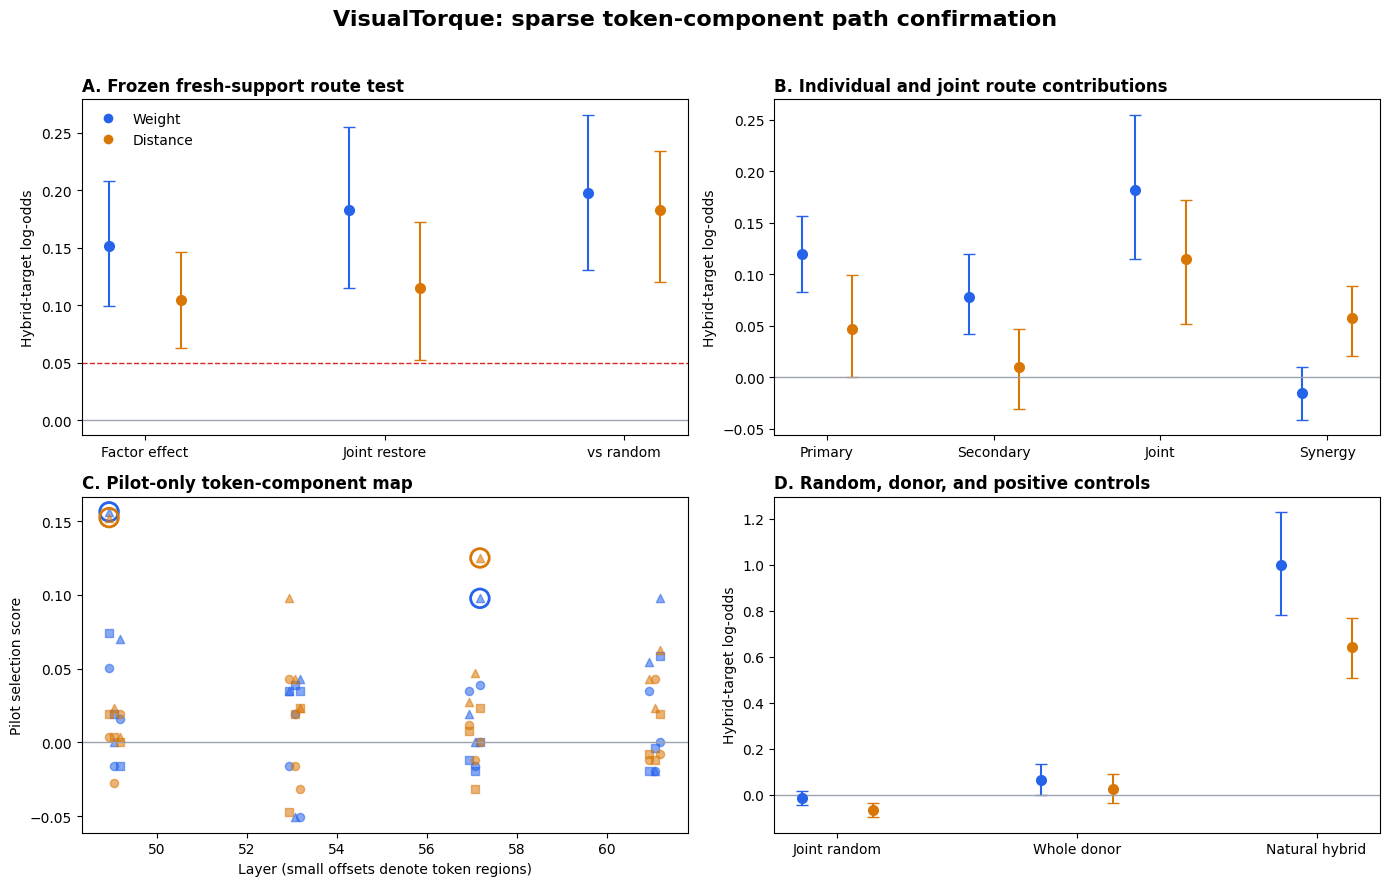

Saved: /content/drive/MyDrive/VisualTorque/results/qwen27b_factor_path_token_component_v2/analysis/figures/factor_path_token_component_confirmation.png


In [17]:
%%cell_progress 16/17 Save the paper-facing route figure
cell_stage('Rendering route effects, individual sites, pilot map, and controls')
import matplotlib.pyplot as plt

factor_colors = {'weight': '#2563EB', 'distance': '#D97706'}
factor_labels = {'weight': 'Weight', 'distance': 'Distance'}

def effect_panel(axis, metrics, labels, title):
    width = 0.30
    for metric_index, metric in enumerate(metrics):
        for factor_index, factor in enumerate(FACTORS):
            row = test_frame[
                (test_frame['factor'] == factor)
                & (test_frame['metric'] == metric)
            ].iloc[0]
            x = metric_index + (factor_index - 0.5) * width
            estimate = float(row['estimate'])
            axis.errorbar(
                [x], [estimate],
                yerr=[[estimate - float(row['ci_low'])],
                      [float(row['ci_high']) - estimate]],
                fmt='o', capsize=4, markersize=7,
                color=factor_colors[factor],
            )
    axis.axhline(0, color='#9CA3AF', linewidth=1)
    axis.set_xticks(range(len(labels)), labels)
    axis.set_ylabel('Hybrid-target log-odds')
    axis.set_title(title, loc='left', fontweight='bold')

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
effect_panel(
    axes[0, 0],
    ['additive_total', 'joint_attenuation', 'joint_specificity'],
    ['Factor effect', 'Joint restore', 'vs random'],
    'A. Frozen fresh-support route test',
)
axes[0, 0].axhline(
    MEDIATION_SESOI_LOGODDS, color='#DC2626', linestyle='--', linewidth=1
)
axes[0, 0].legend(
    handles=[plt.Line2D(
        [0], [0], marker='o', color='w',
        markerfacecolor=factor_colors[factor], markersize=8,
        label=factor_labels[factor],
    ) for factor in FACTORS], frameon=False,
)

effect_panel(
    axes[0, 1],
    ['primary_attenuation', 'secondary_attenuation',
     'joint_attenuation', 'joint_synergy'],
    ['Primary', 'Secondary', 'Joint', 'Synergy'],
    'B. Individual and joint route contributions',
)

component_markers = {'attention': 'o', 'mlp': 's', 'decoder': '^'}
scope_offsets = {
    scope: offset for scope, offset in zip(
        CANDIDATE_SCOPES, (-0.18, -0.06, 0.06, 0.18)
    )
}
for factor in FACTORS:
    subset = candidate_summary[
        (candidate_summary['factor'] == factor)
        & candidate_summary['selectable']
    ]
    for component in CANDIDATE_COMPONENTS:
        current = subset[subset['component'] == component]
        axes[1, 0].scatter(
            current['layer_index'] + current['scope'].map(scope_offsets),
            current['selection_score'],
            marker=component_markers[component], s=35,
            color=factor_colors[factor], alpha=0.55,
        )
    for site in frozen_sites[factor]:
        selected_row = subset[
            (subset['layer_index'] == site['layer_index'])
            & (subset['component'] == site['component'])
            & (subset['scope'] == site['scope'])
        ].iloc[0]
        axes[1, 0].scatter(
            [site['layer_index'] + scope_offsets[site['scope']]],
            [selected_row['selection_score']],
            s=180, facecolors='none', edgecolors=factor_colors[factor],
            linewidths=2,
        )
axes[1, 0].axhline(0, color='#9CA3AF', linewidth=1)
axes[1, 0].set_xlabel('Layer (small offsets denote token regions)')
axes[1, 0].set_ylabel('Pilot selection score')
axes[1, 0].set_title('C. Pilot-only token-component map',
                     loc='left', fontweight='bold')

effect_panel(
    axes[1, 1],
    ['joint_random_attenuation', 'whole_donor', 'natural_hybrid'],
    ['Joint random', 'Whole donor', 'Natural hybrid'],
    'D. Random, donor, and positive controls',
)
fig.suptitle(
    'VisualTorque: sparse token-component path confirmation',
    fontsize=16, fontweight='bold',
)
fig.tight_layout(rect=[0, 0, 1, 0.96])
figure_path = FIGURE_DIR / 'factor_path_token_component_confirmation.png'
fig.savefig(figure_path, dpi=220, bbox_inches='tight')
plt.show()
print('Saved:', figure_path)


In [18]:
%%cell_progress 17/17 Write the decision and completion report
cell_stage('Saving paper-facing table, report, and completion manifest')

paper_rows = []
for factor in FACTORS:
    row = {
        'factor': factor,
        'primary_site': json.dumps(frozen_sites[factor][0], sort_keys=True),
        'secondary_site': json.dumps(frozen_sites[factor][1], sort_keys=True),
        'confirmed': factor_decisions[factor]['confirmed'],
    }
    for metric in (
        'additive_total', 'primary_attenuation', 'secondary_attenuation',
        'joint_attenuation', 'joint_specificity', 'joint_synergy',
        'fanout_min',
    ):
        result = test_for(factor, metric)
        row[f'{metric}_estimate'] = result['estimate']
        row[f'{metric}_ci_low'] = result['ci_low']
        row[f'{metric}_ci_high'] = result['ci_high']
    paper_rows.append(row)
paper_table = pd.DataFrame(paper_rows)
paper_table.to_csv(ANALYSIS_DIR / 'paper_table.csv', index=False)

def interval_text(factor, metric):
    result = test_for(factor, metric)
    return (
        f"{result['estimate']:.3f} "
        f"[{result['ci_low']:.3f}, {result['ci_high']:.3f}]"
    )

lines = [
    '# Token-Component Factor Path: Frozen Result', '',
    f"**Primary decision:** `{primary_decision}`", '',
    '## Design', '',
    (
        'All current scenes are disjoint from the immediately preceding '
        'decision-neutral manifest. Two layer-token-component sites per factor '
        'were selected on four pilot families and frozen before evaluation on '
        'twelve confirmation families, each with two target backgrounds.'
    ), '',
]
for factor in FACTORS:
    primary, secondary = frozen_sites[factor]
    lines.extend([
        f"## {factor.title()}", '',
        f"- Primary site: `{primary['site_key']} / {primary['scope']}`",
        f"- Secondary site: `{secondary['site_key']} / {secondary['scope']}`",
        f"- Fresh factor effect: {interval_text(factor, 'additive_total')}",
        f"- Primary attenuation: {interval_text(factor, 'primary_attenuation')}",
        f"- Secondary attenuation: {interval_text(factor, 'secondary_attenuation')}",
        f"- Joint attenuation: {interval_text(factor, 'joint_attenuation')}",
        f"- Joint specificity over random: "
        f"{interval_text(factor, 'joint_specificity')}",
        f"- Joint synergy: {interval_text(factor, 'joint_synergy')}",
        f"- Gates: `{json.dumps(factor_decisions[factor]['gates'], sort_keys=True)}`",
        '',
    ])
lines.extend([
    '## Claim boundary', '',
    (
        'A positive result identifies a sparse route for this L48 factor '
        'intervention. A negative result rejects only the two frozen sites; it '
        'does not rule out broad token-wide, nonlinear, or redundant routes.'
    ), '',
    '## Audit', '',
    f"- Immediate-prior scene overlap: "
    f"{audit_document['immediate_prior_scene_overlap']}",
    f"- Maximum confirmation self-replay error: "
    f"{audit_document['maximum_confirmation_self_replay_error']:.6f}",
    f"- Maximum joint equal-norm error: "
    f"{audit_document['maximum_joint_norm_relative_error']:.6g}",
    f"- Non-finite values: {audit_document['nonfinite_count']}",
])
report_path = ANALYSIS_DIR / 'FACTOR_PATH_REPORT.md'
report_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')

completion = {
    'schema_version': 'qwen27b-factor-path-token-component-complete-1.0',
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'model_id': MODEL_ID,
    'revision': MODEL_REVISION,
    'primary_decision': primary_decision,
    'factor_decisions': factor_decisions,
    'pilot_families': len(pilot_manifest),
    'confirmation_families': len(confirmation_manifest),
    'confirmation_records': len(record_frame),
    'report_path': str(report_path),
    'figure_path': str(figure_path),
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'manifest_sha256': sha256_file(MANIFEST_PATH),
}
write_json_atomic(SHARED_ROOT / 'RUN_COMPLETE.json', completion)
display(paper_table.round(4))
print('Primary decision:', primary_decision)
print('Report:', report_path)
print('Run complete:', SHARED_ROOT / 'RUN_COMPLETE.json')


Write the decision and completion report:  94%|#########4| 16/17 [00:00<?, ?cell/s]

,factor,primary_site,secondary_site,confirmed,additive_total_estimate,additive_total_ci_low,additive_total_ci_high,primary_attenuation_estimate,primary_attenuation_ci_low,primary_attenuation_ci_high,...,joint_attenuation_ci_high,joint_specificity_estimate,joint_specificity_ci_low,joint_specificity_ci_high,joint_synergy_estimate,joint_synergy_ci_low,joint_synergy_ci_high,fanout_min_estimate,fanout_min_ci_low,fanout_min_ci_high
0,weight,"{""component"": ""decoder"", ""layer_index"": 49, ""p...","{""component"": ""decoder"", ""layer_index"": 57, ""p...",True,0.1510,0.0990,0.2083,0.1198,0.0833,0.1563,...,0.2552,0.1979,0.1302,0.2656,-0.0156,-0.0417,0.0104,0.1250,0.0625,0.1875
1,distance,"{""component"": ""decoder"", ""layer_index"": 49, ""p...","{""component"": ""decoder"", ""layer_index"": 57, ""p...",True,0.1042,0.0625,0.1458,0.0469,0.0000,0.0990,...,0.1719,0.1823,0.1198,0.2344,0.0573,0.0208,0.0885,0.0729,0.0312,0.1250


Primary decision: sparse_token_component_route_confirmed_for_both_factors
Report: /content/drive/MyDrive/VisualTorque/results/qwen27b_factor_path_token_component_v2/analysis/FACTOR_PATH_REPORT.md
Run complete: /content/drive/MyDrive/VisualTorque/results/qwen27b_factor_path_token_component_v2/RUN_COMPLETE.json
